In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load dataset
df = pd.read_csv("data/archive_week10.zip", engine="python", on_bad_lines="skip")

# Set plot style
sns.set(rc={"axes.facecolor":"#FFFAF0","figure.facecolor":"#FFFAF0"})
sns.set_context("poster", font_scale=.7)

# Show dataset shape and info
print("Dataset Shape:", df.shape)
df.info()

# Remove duplicates
print("Duplicates:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

# Count missing values
missing_data = pd.DataFrame({
    "Total No. of Missing Values": df.isnull().sum()
})
missing_data["% of Missing Values"] = (
    missing_data["Total No. of Missing Values"] / len(df) * 100
).round(2)

# Show missing values and summary statistics
display(missing_data)
display(df.describe(include="O").T.round(2))

Dataset Shape: (50000, 2)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
Duplicates: 418


,Total No. of Missing Values,% of Missing Values
review,0,0.0
sentiment,0,0.0


,count,unique,top,freq
review,49582,49582,One of the other reviewers has mentioned that ...,1
sentiment,49582,2,positive,24884


Text(0.5, 1.0, 'Distribution of Sentiment Classes')

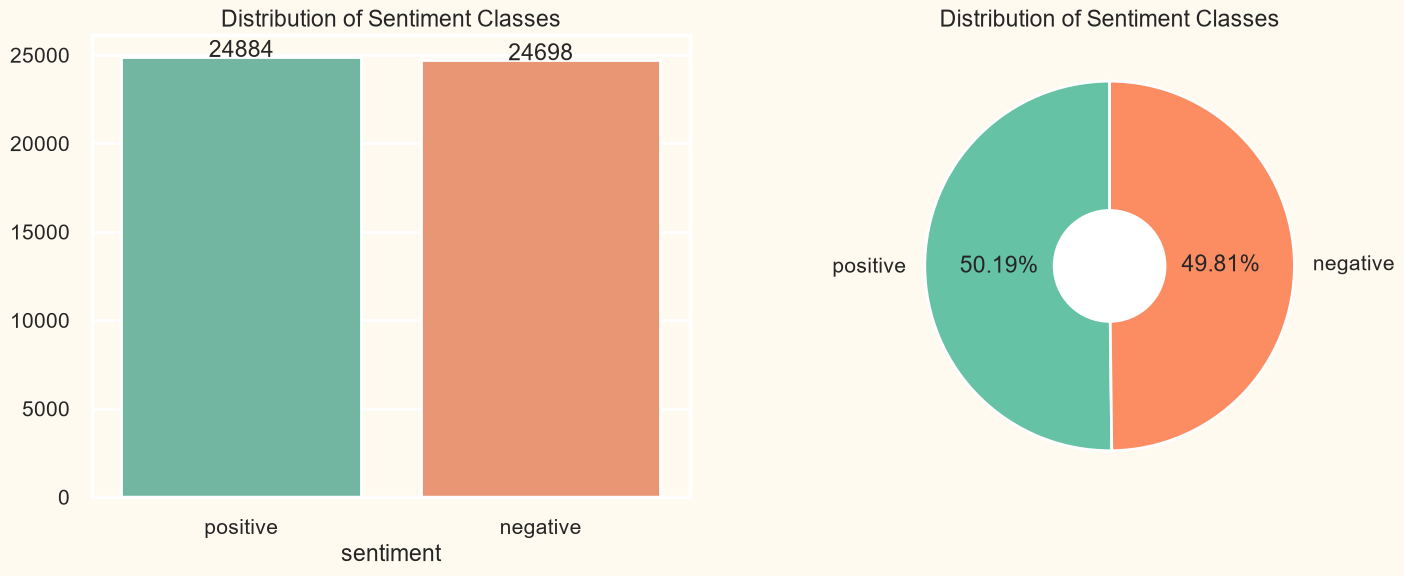

In [3]:
classes = ["positive", "negative"]
sentiment_counts = df["sentiment"].value_counts()

# Plot sentiment distribution
plt.figure(figsize=(17,6))

# Bar chart
plt.subplot(1,2,1)
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
    order=classes,
    palette="Set2"
)
plt.title("Distribution of Sentiment Classes")
for i, v in enumerate(sentiment_counts.values):
    plt.text(i, v, str(v), ha="center")

# Donut chart
plt.subplot(1,2,2)
plt.pie(
    sentiment_counts,
    labels=classes,
    autopct="%.2f%%",
    colors=sns.color_palette("Set2",2),
    startangle=90
)
plt.gca().add_artist(plt.Circle((0,0),0.3,color="white"))
plt.title("Distribution of Sentiment Classes")